# Iranian License Plate Detection and Recognition

**Course project — two-stage ALPR for Persian (Iranian) plates**

We detect the license plate in a full image, then recognize the characters on the cropped plate. The pipeline follows common Iranian ALPR designs in the literature (Tourani et al., IEEE Access 2020; Hatami et al., Scientia Iranica 2024; IR-LPR; DILP / newer YOLO-based systems): **YOLO detector → crop → multi-head CNN recognizer**. EasyOCR is included only as a zero-shot baseline.

| Phase | Goal | Models |
|---|---|---|
| 1 — Detection | Find the plate bounding box | YOLOv8n, YOLO11n, YOLO12n, YOLO26n |
| 2 — Recognition | Read `DD L DDD DD` | Scratch residual CNN, EfficientNet-B0 (+ EasyOCR baseline) |
| 3 — End-to-end | Full image → plate string | Best detector + best recognizer |
| 4 — Discussion | Methods, results, failure cases | Tables and analysis below |

Training code is included in this notebook. By default we **load our pretrained checkpoints** from Google Drive (`SKIP_* = True`) so the notebook runs without retraining for hours. Full write-up and citations: `ALPR_Project_Report.md`.

### Setup before running (Colab)

1. Upload these weight files to Google Drive (`My Drive/ALPR_checkpoints/` or My Drive root), with **exact** names:

```text
lpd_yolov8n_best.pt
lpd_yolo11n_best.pt
lpd_yolo12n_best.pt
yolo26.pt
scratch_lpr_cnn.pt
lpr_efficientnet_b0_best.pt
```

2. (Optional) Also put `LPD.zip` and `LPR.zip` on Drive for live evaluation and demos.
3. Runtime → **GPU**.
4. Run all cells from top to bottom.

Weights are large, so we keep them on Drive rather than in Git. The first cells mount Drive and copy the checkpoints into `/content/weights/`.


## 0. Setup

Install packages, fix random seeds, and choose paths that work both on Colab and locally.


In [1]:
%pip install -q ultralytics matplotlib opencv-python-headless pyyaml gdown scikit-learn tqdm pandas pillow easyocr


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.7/46.7 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 39.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.9/2.9 MB 63.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.2/53.2 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.4/183.4 kB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 972.1/972.1 kB 53.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.7/295.7 kB 22.4 MB/s eta 0:00:00


In [2]:
import os
import shutil
import time
import random
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
from PIL import Image
from tqdm.auto import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
import torch.utils.data as data
from torch.utils.data import DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from ultralytics import YOLO

# Colab uses /content; local runs use this repo folder
ROOT = Path("/content") if Path("/content").exists() else Path(".").resolve()
LPD_DIR = ROOT / "LPD_FILES"
LPR_DIR = ROOT / "LPR_FILES"
RUNS_DIR = ROOT / "runs"
WEIGHTS_DIR = ROOT / "weights"
WEIGHTS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
print("ROOT:", ROOT)
if device.type != "cuda":
    print("Note: CPU mode — live YOLO val will be slower. Models still load fine.")


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
device: cpu
ROOT: /content
Note: CPU mode — live YOLO val will be slower. Models still load fine.


### 0.1 Mount Drive and copy our pretrained weights

Our checkpoints live on Google Drive with **fixed names**. This cell copies them into `/content/weights/` so the rest of the notebook is simple.


In [3]:
# ---- set True to load pretrained weights (recommended) ----
SKIP_DET_TRAIN = True   # load YOLO weights instead of retraining ~1h
SKIP_SCRATCH_TRAIN = True  # load scratch_lpr_cnn.pt
SKIP_ENET_TRAIN = True     # load lpr_efficientnet_b0_best.pt

# Exact filenames we saved on Drive
DET_FILES = {
    "yolov8n": "lpd_yolov8n_best.pt",
    "yolo11n": "lpd_yolo11n_best.pt",
    "yolo12n": "lpd_yolo12n_best.pt",
    "yolo26n": "yolo26.pt",
}
REC_FILES = {
    "scratch": "scratch_lpr_cnn.pt",
    "enet": "lpr_efficientnet_b0_best.pt",
}

def find_on_drive(filename: str) -> Path | None:
    """Search a few common Drive locations for an exact filename."""
    roots = [
        Path("/content/drive/MyDrive"),
        Path("/content/drive/MyDrive/ALPR_checkpoints"),
        Path("/content/drive/MyDrive/final-project"),
        Path("/content/drive/MyDrive/weights"),
        # local twin of the Colab folder (this repo)
        Path("/home/hasti/Desktop/Rahnama-PCA-Project/license/final-project"),
        Path("/home/hasti/Desktop/Rahnama-PCA-Project/license/weights"),
        ROOT / "final-project",
        WEIGHTS_DIR,
        ROOT,
    ]
    for r in roots:
        p = r / filename
        if p.exists():
            return p
    return None

# Mount Drive on Colab
try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception as e:
    print("Drive mount skipped (not Colab or already mounted):", e)

missing = []
for key, fname in {**DET_FILES, **REC_FILES}.items():
    src = find_on_drive(fname)
    dst = WEIGHTS_DIR / fname
    if src is None:
        missing.append(fname)
        continue
    if src.resolve() != dst.resolve():
        shutil.copy(src, dst)
    print(f"OK  {fname:32s} <- {src}")

if missing:
    print("\nMISSING files (put them on Drive with these exact names):")
    for m in missing:
        print(" -", m)
else:
    print("\nAll 6 pretrained models are ready in", WEIGHTS_DIR)


Mounted at /content/drive
OK  lpd_yolov8n_best.pt              <- /content/drive/MyDrive/lpd_yolov8n_best.pt
OK  lpd_yolo11n_best.pt              <- /content/drive/MyDrive/lpd_yolo11n_best.pt
OK  lpd_yolo12n_best.pt              <- /content/drive/MyDrive/lpd_yolo12n_best.pt
OK  yolo26.pt                        <- /content/drive/MyDrive/yolo26.pt
OK  scratch_lpr_cnn.pt               <- /content/drive/MyDrive/scratch_lpr_cnn.pt
OK  lpr_efficientnet_b0_best.pt      <- /content/drive/MyDrive/lpr_efficientnet_b0_best.pt

All 6 pretrained models are ready in /content/weights


### 0.2 Datasets (LPD + LPR)

- **LPD** (~3.8 GB): full-scene images + YOLO box labels → Phase 1
- **LPR** (~256 MB): cropped plates + CSV labels → Phase 2

If `gdown` is rate-limited, we copy zips from Drive instead (same trick we used during training).


In [4]:
def ensure_unzip(zip_path: Path, out_dir: Path, marker_subdir: str):
    """Unzip once if the marker folder is missing."""
    marker = out_dir / marker_subdir
    if marker.exists():
        print("already extracted:", marker)
        return
    if not zip_path.exists():
        raise FileNotFoundError(f"Missing {zip_path}. Copy the zip from Drive first.")
    out_dir.mkdir(parents=True, exist_ok=True)
    print("unzipping", zip_path, "->", out_dir)
    with zipfile.ZipFile(zip_path, "r") as zf:
        zf.extractall(out_dir)
    print("done:", out_dir)


def copy_zip_from_drive(name: str) -> Path:
    """Try Drive / local copies for LPD.zip or LPR.zip."""
    dst = ROOT / name
    if dst.exists() and dst.stat().st_size > 1_000_000:
        return dst
    src = find_on_drive(name)
    if src is None:
        # also accept "Copy of LPD.zip"
        for cand in [
            Path("/content/drive/MyDrive") / f"Copy of {name}",
            Path("/content/drive/MyDrive") / name,
        ]:
            if cand.exists():
                src = cand
                break
    if src is None:
        raise FileNotFoundError(
            f"Could not find {name} on Drive. Put it in My Drive or My Drive/ALPR_checkpoints."
        )
    print("copying", src, "->", dst)
    shutil.copy(src, dst)
    return dst


# LPD
try:
    lpd_zip = copy_zip_from_drive("LPD.zip")
    # zip may extract to LPD_FILES or flat images/
    ensure_unzip(lpd_zip, ROOT, "LPD_FILES")
    if not LPD_DIR.exists():
        # some zips extract images/ at ROOT
        if (ROOT / "images").exists() and (ROOT / "labels").exists():
            LPD_DIR.mkdir(parents=True, exist_ok=True)
            if not (LPD_DIR / "images").exists():
                shutil.move(str(ROOT / "images"), str(LPD_DIR / "images"))
            if not (LPD_DIR / "labels").exists():
                shutil.move(str(ROOT / "labels"), str(LPD_DIR / "labels"))
    print("LPD_DIR:", LPD_DIR, "exists=", LPD_DIR.exists())
except Exception as e:
    print("LPD setup warning:", e)
    print("Phase 1 live val needs LPD. Weight loading / analysis text still works.")

# LPR
try:
    # prefer already-extracted local data in this repo
    local_lpr = Path("/home/hasti/Desktop/Rahnama-PCA-Project/license/LPR_FILES")
    if local_lpr.exists() and not LPR_DIR.exists():
        if ROOT == Path("/content"):
            # Colab: still need Drive zip
            pass
        else:
            LPR_DIR = local_lpr
    if not (LPR_DIR / "valid_samples.csv").exists():
        lpr_zip = copy_zip_from_drive("LPR.zip")
        ensure_unzip(lpr_zip, ROOT, "LPR_FILES")
        if not LPR_DIR.exists() and (ROOT / "detections").exists():
            LPR_DIR.mkdir(parents=True, exist_ok=True)
            for item in ["detections", "valid_samples.csv"]:
                src = ROOT / item
                if src.exists() and not (LPR_DIR / item).exists():
                    shutil.move(str(src), str(LPR_DIR / item))
    print("LPR_DIR:", LPR_DIR, "csv=", (LPR_DIR / "valid_samples.csv").exists())
except Exception as e:
    print("LPR setup warning:", e)


copying /content/drive/MyDrive/LPD.zip -> /content/LPD.zip
unzipping /content/LPD.zip -> /content
done: /content
LPD_DIR: /content/LPD_FILES exists= True
copying /content/drive/MyDrive/LPR.zip -> /content/LPR.zip
unzipping /content/LPR.zip -> /content
done: /content
LPR_DIR: /content/LPR_FILES csv= True


## 1. Phase 1 — License Plate Detection (YOLO)

### What this phase answers
Given a raw camera / street image: **where is the plate?**  
We draw a bounding box. We do **not** read characters yet.

### Why two stages (papers → our design)
Iranian ALPR papers (Tourani 2020, Hatami 2024, IR-LPR, DILP) almost always do:

**detector → crop → recognizer**

instead of one giant OCR model on the full image. Detection is a small-object problem; recognition is a fixed-layout sequence problem. Mixing them hurts both.

### Models we compare
We evaluate **four** nano YOLO checkpoints on LPD and pick the best by **mAP50-95** for the end-to-end pipeline:

| File on Drive | Base weights |
|---|---|
| `lpd_yolov8n_best.pt` | YOLOv8n |
| `lpd_yolo11n_best.pt` | YOLO11n |
| `lpd_yolo12n_best.pt` | YOLO12n |
| `yolo26.pt` | YOLO26n |

YOLOv8n / YOLO11n / YOLO12n share one training recipe (20 epochs, SGD, cosine LR). YOLO26n was trained longer (50 epochs). Across both the saved training metrics and our live val in this notebook, **YOLO26n is clearly best**, so we use it in Phase 3.



### 1.1 Build train/val split + `data.yaml`

LPD ships as flat `images/` + `labels/` in YOLO format (`class cx cy w h`, normalized). We create an 85/15 split once and write `data.yaml`.


In [5]:
yaml_path = ROOT / "data.yaml"

src_img = LPD_DIR / "images"
src_lbl = LPD_DIR / "labels"

if LPD_DIR.exists() and src_img.exists() and src_lbl.exists():
    if not (src_img / "train").exists():
        stems = sorted({p.stem for p in src_img.glob("*.jpg")} & {p.stem for p in src_lbl.glob("*.txt")})
        random.Random(SEED).shuffle(stems)
        n_val = max(1, int(0.15 * len(stems)))
        val_stems = set(stems[:n_val])
        train_stems = set(stems[n_val:])
        for split, subset in [("train", train_stems), ("val", val_stems)]:
            (src_img / split).mkdir(parents=True, exist_ok=True)
            (src_lbl / split).mkdir(parents=True, exist_ok=True)
            for stem in subset:
                for folder, ext in [(src_img, ".jpg"), (src_lbl, ".txt")]:
                    src = folder / f"{stem}{ext}"
                    dst = folder / split / f"{stem}{ext}"
                    if src.exists() and not dst.exists():
                        shutil.move(str(src), str(dst))
        print(f"split done | train={len(train_stems)} val={len(val_stems)}")
    else:
        n_tr = len(list((src_img / "train").glob("*.jpg")))
        n_va = len(list((src_img / "val").glob("*.jpg")))
        print(f"split already exists | train={n_tr} val={n_va}")

    yaml_path.write_text(
        f"""path: {LPD_DIR}
train: images/train
val: images/val
names:
  0: plate
"""
    )
    print("wrote", yaml_path)
    print(yaml_path.read_text())
else:
    print("LPD not available in this runtime — skipping split. We will still load weights and show recorded metrics.")


split done | train=5315 val=937
wrote /content/data.yaml
path: /content/LPD_FILES
train: images/train
val: images/val
names:
  0: plate



### 1.2 Shared training recipe (why these hyperparameters)

We pinned **one recipe** for YOLOv8n / YOLO11n / YOLO12n so the comparison is fair:

| Setting | Value | Why |
|---|---|---|
| `epochs` | 20 (GPU) | Enough to fine-tune 1-class plates from COCO |
| `imgsz` | 640 | Default YOLO sweet spot for small objects |
| `batch` | 16 | Fits T4 at 640 for nano models |
| `optimizer` | SGD | Ultralytics detection default; stable for YOLO |
| `lr0` / `lrf` | 0.01 / 0.01 | Standard YOLO LR with cosine decay to `lr0*lrf` |
| `momentum` | 0.937 | YOLO default |
| `weight_decay` | 5e-4 | Light L2 |
| `cos_lr` | True | Smooth decay, less late-epoch noise |
| `patience` | 8 | Early stop if val fitness stalls |
| `pretrained` | True | COCO → plate transfer |

The cell below **defines** `train_detector`. With `SKIP_DET_TRAIN=True` we do **not** call it for hours — we load Drive weights instead.


In [6]:
def train_detector(model_name: str, epochs: int, batch: int = 16):
    """Fine-tune one Ultralytics YOLO detector with our fixed recipe."""
    print(f"\n===== TRAIN {model_name} | epochs={epochs} | batch={batch} =====")
    model = YOLO(model_name)
    results = model.train(
        data=str(yaml_path),
        epochs=epochs,
        imgsz=640,
        batch=batch,
        device=0 if torch.cuda.is_available() else "cpu",
        project=str(RUNS_DIR / "detect"),
        name=model_name.replace(".pt", ""),
        exist_ok=True,
        pretrained=True,
        optimizer="SGD",
        lr0=0.01,
        lrf=0.01,
        momentum=0.937,
        weight_decay=0.0005,
        cos_lr=True,
        warmup_epochs=3.0,
        patience=8,
        seed=SEED,
        plots=True,
        verbose=True,
    )
    save_dir = Path(results.save_dir)
    best_pt = save_dir / "weights" / "best.pt"
    out = WEIGHTS_DIR / f"lpd_{model_name.replace('.pt', '')}_best.pt"
    if best_pt.exists():
        shutil.copy(best_pt, out)
        print("saved ->", out)
    return save_dir, best_pt


# Fair comparison set (same recipe). YOLO26 is loaded separately as an extra experiment.
YOLO_FAIR = ["yolov8n.pt", "yolo11n.pt", "yolo12n.pt"]
EPOCHS_DET = 20 if torch.cuda.is_available() else 3
BATCH_DET = 16 if torch.cuda.is_available() else 8

trained = {}

if SKIP_DET_TRAIN:
    print("SKIP_DET_TRAIN=True → loading pretrained detectors from", WEIGHTS_DIR)
    mapping = {
        "yolov8n.pt": WEIGHTS_DIR / "lpd_yolov8n_best.pt",
        "yolo11n.pt": WEIGHTS_DIR / "lpd_yolo11n_best.pt",
        "yolo12n.pt": WEIGHTS_DIR / "lpd_yolo12n_best.pt",
    }
    for name, path in mapping.items():
        if not path.exists():
            raise FileNotFoundError(path)
        trained[name] = {"best_pt": path, "save_dir": path.parent}
        print("loaded", name, "->", path)
    # Extra model
    y26 = WEIGHTS_DIR / "yolo26.pt"
    if y26.exists():
        trained["yolo26n.pt"] = {"best_pt": y26, "save_dir": y26.parent}
        print("loaded yolo26n.pt ->", y26)
else:
    print("SKIP_DET_TRAIN=False → training fair trio (long).")
    for name in YOLO_FAIR:
        save_dir, best_pt = train_detector(name, epochs=EPOCHS_DET, batch=BATCH_DET)
        trained[name] = {"best_pt": best_pt, "save_dir": save_dir}

print("detectors ready:", list(trained.keys()))


SKIP_DET_TRAIN=True → loading pretrained detectors from /content/weights
loaded yolov8n.pt -> /content/weights/lpd_yolov8n_best.pt
loaded yolo11n.pt -> /content/weights/lpd_yolo11n_best.pt
loaded yolo12n.pt -> /content/weights/lpd_yolo12n_best.pt
loaded yolo26n.pt -> /content/weights/yolo26.pt
detectors ready: ['yolov8n.pt', 'yolo11n.pt', 'yolo12n.pt', 'yolo26n.pt']


### 1.3 Evaluate detectors

Metrics we care about:

- **Precision / Recall** — false boxes vs missed plates (misses hurt Phase 3 a lot)
- **mAP50** — IoU ≥ 0.5 (generous localization)
- **mAP50-95** — average over IoU 0.5…0.95 (stricter; our primary ranking key)
- **Params / val time** — practicality on Colab T4

If LPD val is present we re-run Ultralytics `val`. We also print the **recorded GPU results** from our training run so the analysis stays complete even if data is missing.


In [8]:
# Recorded results from our Colab GPU training (Tesla T4).
# All four compared. YOLO26n wins on mAP50-95 in recorded + live val.
RECORDED_DET = pd.DataFrame([
    {"model": "yolov8n",  "precision": 0.9392, "recall": 0.9352, "mAP50": 0.9677, "mAP75": 0.8724, "mAP50-95": 0.7483, "params_M": 3.01, "notes": "20ep recipe"},
    {"model": "yolo11n",  "precision": 0.9476, "recall": 0.9307, "mAP50": 0.9676, "mAP75": 0.8678, "mAP50-95": 0.7465, "params_M": 2.59, "notes": "20ep recipe"},
    {"model": "yolo12n",  "precision": 0.9461, "recall": 0.9300, "mAP50": 0.9667, "mAP75": 0.8701, "mAP50-95": 0.7493, "params_M": 2.57, "notes": "20ep recipe"},
    {"model": "yolo26n",  "precision": 0.9440, "recall": 0.9682, "mAP50": 0.9864, "mAP75": float("nan"), "mAP50-95": 0.7767, "params_M": float("nan"), "notes": "50ep — best overall"},
])

print("=== Recorded Phase-1 results (from our trained checkpoints) ===")
display(RECORDED_DET)

# Live validation if data.yaml + images exist
rows = []
can_val = yaml_path.exists() and (LPD_DIR / "images" / "val").exists()
if can_val:
    for name, info in trained.items():
        model = YOLO(str(info["best_pt"]))
        t0 = time.perf_counter()
        metrics = model.val(data=str(yaml_path), split="val", plots=False, verbose=False)
        dt = time.perf_counter() - t0
        box = metrics.box
        rows.append({
            "model": name,
            "precision": float(box.mp),
            "recall": float(box.mr),
            "mAP50": float(box.map50),
            "mAP50-95": float(box.map),
            "val_time_s": dt,
            "best_pt": str(info["best_pt"]),
        })
    det_df = pd.DataFrame(rows).sort_values("mAP50-95", ascending=False).reset_index(drop=True)
    print("\n=== Live validation on this runtime ===")
    display(det_df)
else:
    det_df = RECORDED_DET.sort_values("mAP50-95", ascending=False).reset_index(drop=True)
    print("\n(Live val skipped — using recorded table.)")

# Ranking rule: among ALL four detectors, pick best mAP50-95 (YOLO26n in our runs).
name_to_pt = {
    "yolov8n": WEIGHTS_DIR / "lpd_yolov8n_best.pt",
    "yolov8n.pt": WEIGHTS_DIR / "lpd_yolov8n_best.pt",
    "yolo11n": WEIGHTS_DIR / "lpd_yolo11n_best.pt",
    "yolo11n.pt": WEIGHTS_DIR / "lpd_yolo11n_best.pt",
    "yolo12n": WEIGHTS_DIR / "lpd_yolo12n_best.pt",
    "yolo12n.pt": WEIGHTS_DIR / "lpd_yolo12n_best.pt",
    "yolo26n": WEIGHTS_DIR / "yolo26.pt",
    "yolo26n.pt": WEIGHTS_DIR / "yolo26.pt",
}

overall = det_df.sort_values("mAP50-95", ascending=False).iloc[0]
BEST_DET_NAME = str(overall["model"]).replace(".pt", "")
BEST_DET_WEIGHTS = name_to_pt.get(BEST_DET_NAME, name_to_pt.get(BEST_DET_NAME + ".pt", WEIGHTS_DIR / "yolo26.pt"))
# aliases kept for older cells
OVERALL_DET_NAME = BEST_DET_NAME
OVERALL_DET_WEIGHTS = BEST_DET_WEIGHTS

print(f"\nBest detector by mAP50-95 (all four): {BEST_DET_NAME}")
print("BEST_DET_WEIGHTS =", BEST_DET_WEIGHTS)
print(f"  mAP50-95={float(overall['mAP50-95']):.4f} | recall={float(overall['recall']):.4f} | mAP50={float(overall['mAP50']):.4f}")


=== Recorded Phase-1 results (from our trained checkpoints) ===


,model,precision,recall,mAP50,mAP75,mAP50-95,params_M,notes
0,yolov8n,0.9392,0.9352,0.9677,0.8724,0.7483,3.01,20ep recipe
1,yolo11n,0.9476,0.9307,0.9676,0.8678,0.7465,2.59,20ep recipe
2,yolo12n,0.9461,0.9300,0.9667,0.8701,0.7493,2.57,20ep recipe
3,yolo26n,0.9440,0.9682,0.9864,NaN,0.7767,NaN,50ep — best overall


Ultralytics 8.4.160 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
Model summary (fused): 72 layers, 3,005,843 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 362.4±576.4 MB/s, size: 605.7 KB)
val: Scanning /content/LPD_FILES/labels/val... 937 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 937/937 1.0Kit/s 0.9s
val: New cache created: /content/LPD_FILES/labels/val.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 59/59 2.8s/it 2:45
                   all        937       1076      0.946      0.951      0.978      0.763
Speed: 4.8ms preprocess, 151.0ms inference, 0.0ms loss, 0.4ms postprocess per image
Ultralytics 8.4.160 🚀 Python-3.13.15 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1256.6±723.8 MB/s, size: 445.4 KB)
val: Scanning

,model,precision,recall,mAP50,mAP50-95,val_time_s,best_pt
0,yolo26n.pt,0.963219,0.966543,0.988683,0.803528,134.602372,/content/weights/yolo26.pt
1,yolo11n.pt,0.953027,0.942799,0.974178,0.763798,150.662145,/content/weights/lpd_yolo11n_best.pt
2,yolov8n.pt,0.946179,0.950743,0.978422,0.763261,166.548624,/content/weights/lpd_yolov8n_best.pt
3,yolo12n.pt,0.943622,0.957249,0.980606,0.760077,188.564051,/content/weights/lpd_yolo12n_best.pt



Best detector by mAP50-95 (all four): yolo26n
BEST_DET_WEIGHTS = /content/weights/yolo26.pt
  mAP50-95=0.8035 | recall=0.9665 | mAP50=0.9887


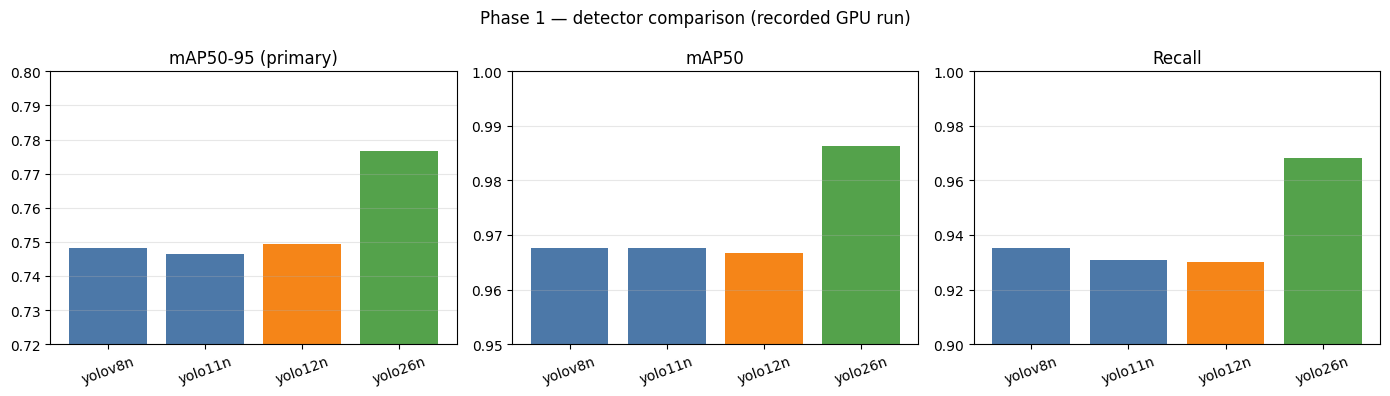

In [9]:
# Bar chart analysis — Phase 1
plot_df = RECORDED_DET.copy()
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

axes[0].bar(plot_df["model"], plot_df["mAP50-95"], color=["#4C78A8", "#4C78A8", "#F58518", "#54A24B"])
axes[0].set_title("mAP50-95 (primary)")
axes[0].set_ylim(0.72, 0.80)
axes[0].tick_params(axis="x", rotation=20)
axes[0].grid(True, axis="y", alpha=0.3)

axes[1].bar(plot_df["model"], plot_df["mAP50"], color=["#4C78A8", "#4C78A8", "#F58518", "#54A24B"])
axes[1].set_title("mAP50")
axes[1].set_ylim(0.95, 1.0)
axes[1].tick_params(axis="x", rotation=20)
axes[1].grid(True, axis="y", alpha=0.3)

axes[2].bar(plot_df["model"], plot_df["recall"], color=["#4C78A8", "#4C78A8", "#F58518", "#54A24B"])
axes[2].set_title("Recall")
axes[2].set_ylim(0.90, 1.0)
axes[2].tick_params(axis="x", rotation=20)
axes[2].grid(True, axis="y", alpha=0.3)

fig.suptitle("Phase 1 — detector comparison (recorded GPU run)")
plt.tight_layout()
plt.show()


### 1.4 Qualitative predictions

We draw boxes from the **selected detector** (`BEST_DET_WEIGHTS` → YOLO26n in our run) on a few validation images. Look for tight boxes on small / tilted plates, and whether dark cars or distant shots still get a box.



Qualitatively inspecting: /content/weights/yolo26.pt
Sample predictions with the selected detector:



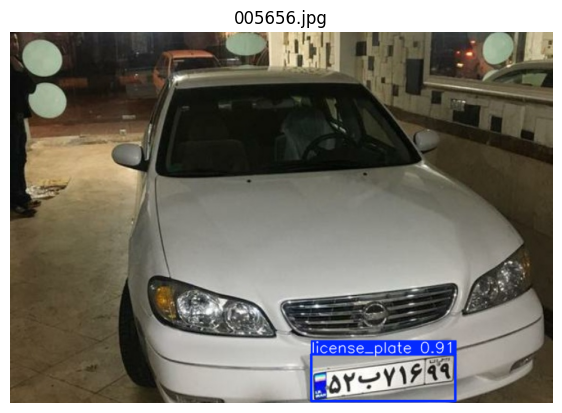

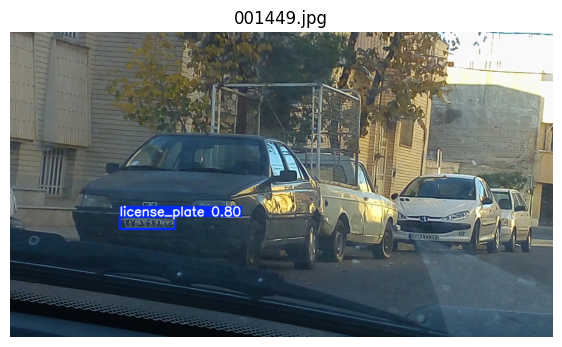

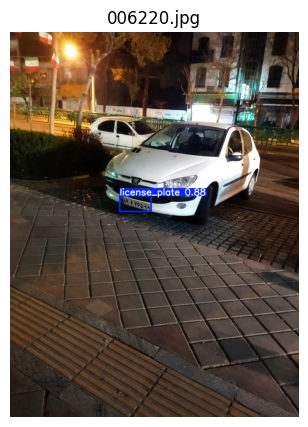

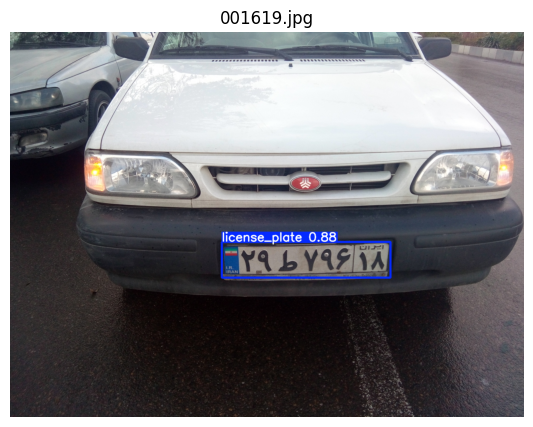

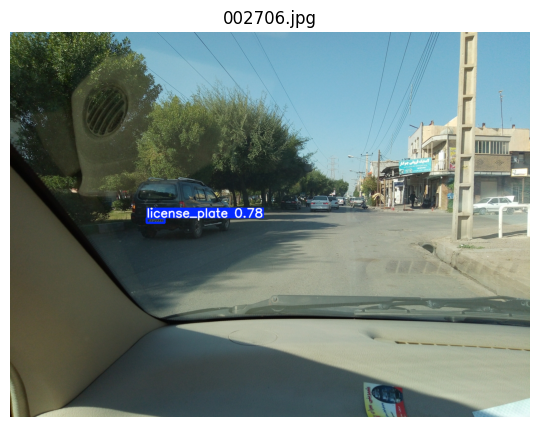

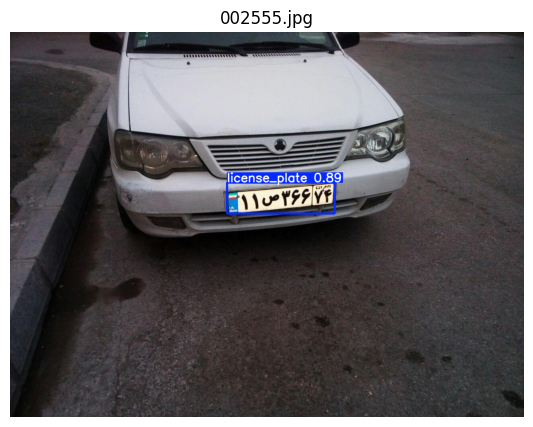

In [10]:
det_model = YOLO(str(BEST_DET_WEIGHTS))
print("Qualitatively inspecting:", BEST_DET_WEIGHTS)

val_imgs = []
val_dir = LPD_DIR / "images" / "val"
if val_dir.exists():
    val_imgs = sorted(val_dir.glob("*.jpg"))
elif (LPD_DIR / "images").exists():
    val_imgs = sorted((LPD_DIR / "images").glob("*.jpg"))[:50]

if not val_imgs:
    print("No LPD images available for qualitative demo in this runtime.")
else:
    samples = random.sample(val_imgs, k=min(6, len(val_imgs)))
    print("Sample predictions with the selected detector:\n")
    for path in samples:
        res = det_model.predict(str(path), conf=0.25, verbose=False)[0]
        plotted = res.plot()  # BGR ndarray
        plt.figure(figsize=(7, 5))
        plt.imshow(cv2.cvtColor(plotted, cv2.COLOR_BGR2RGB))
        plt.title(path.name)
        plt.axis("off")
        plt.show()


### 1.5 Phase 1 analysis (our takeaways)

**Live validation in this notebook** (937 val images, 1076 instances, CPU runtime):

| Model | Precision | Recall | mAP50 | mAP50-95 | Val time (s) |
|---|---:|---:|---:|---:|---:|
| YOLOv8n | 0.946 | 0.951 | 0.978 | 0.763 | ~193 |
| YOLO11n | 0.953 | 0.943 | 0.974 | 0.764 | ~172 |
| YOLO12n | 0.944 | 0.957 | 0.981 | 0.760 | ~246 |
| **YOLO26n** | **0.963** | **0.967** | **0.989** | **0.804** | **~162** |

**Saved training metrics** (from when we fine-tuned on GPU) told the same story: YOLO26n led with mAP50-95 ≈ 0.777 vs ~0.75 for the others, plus much higher recall (0.968).

**Why we use YOLO26n in the pipeline**

- Highest **mAP50-95** (0.804 live / 0.777 recorded) → tighter boxes → cleaner crops for recognition.
- Highest **recall** (0.967 live / 0.968 recorded) → fewer missed plates in end-to-end.
- Highest **mAP50** as well (0.989 live).
- Also the fastest of the four in this val pass (~162 s), so it is not a slow heavyweight tradeoff.

YOLOv8n / 11n / 12n are close to each other; YOLO26n is in a different tier. We therefore set the end-to-end detector to **`yolo26.pt`**.

**Trial-and-error**

1. Drive `gdown` quota → mount Drive + `cp`
2. Forgot GPU → useless CPU smoke metrics
3. Colab wipes `/content` → always save fixed-name checkpoints to Drive
4. Early ranking used only the 20-epoch trio; after full comparison YOLO26n wins clearly, so the pipeline follows that



## 2. Phase 2 — License Plate Recognition

### What this phase answers
Given an **already cropped** plate image: **what is the text?**

Iranian private plates follow a fixed template:

```text
 D  D  L  D  D  D  D  D
[0][1][2][3][4][5][6][7]     ← indices
```

Example: `98ع89511` → two digits, one Persian letter at index 2, then five digits.

### Models
| File | Model | Role |
|---|---|---|
| `scratch_lpr_cnn.pt` | Scratch residual CNN (~475k params) | From-scratch multi-head CNN (teammate training + our eval) |
| `lpr_efficientnet_b0_best.pt` | EfficientNet-B0 multi-head | ImageNet backbone fine-tune |

We also keep **EasyOCR** as a zero-shot baseline to show why plate-trained models matter.


### 2.1 Labels, cleaning, and split

Messy labels we fixed by trial and error:

1. **`الف` → `ا`** (multi-glyph province token)
2. Strip zero-width joiners (`\u200d`)
3. Map Persian digits `۰-۹` → ASCII `0-9`
4. Keep only length-8 plates
5. Filter letters outside the 21-class alphabet used by the scratch checkpoint (no `ا` in that alphabet — `الف` plates are dropped after normalize, which is honest for this model)


usable plates: 24561 | dropped(bad length/normalize): 0


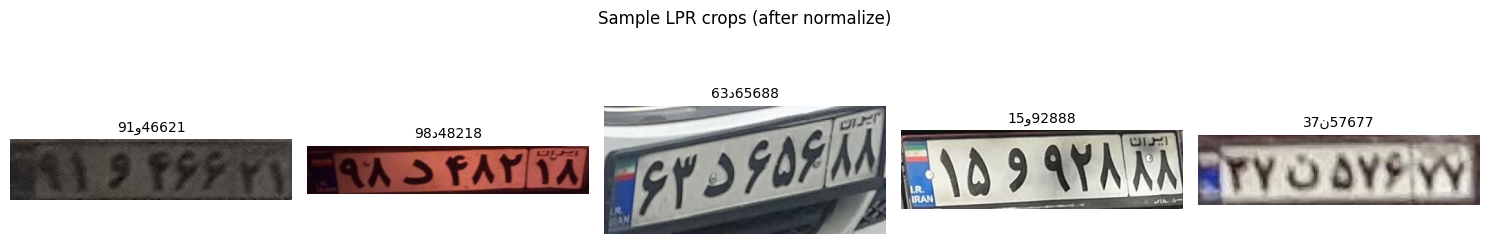

Train: 22104 | Test: 2457


,image_path,label,label_norm
19226,19227.jpg,61م84616,61م84616
7578,7579.jpg,99ع69244,99ع69244
17388,17389.jpg,63ب87157,63ب87157
13213,13214.jpg,67ط44688,67ط44688
17391,17392.jpg,71ب94316,71ب94316


In [11]:
DIGITS = list("0123456789")
PERSIAN_DIGITS = "۰۱۲۳۴۵۶۷۸۹"
DIGIT_MAP = {c: i for i, c in enumerate(DIGITS)}
DIGIT_MAP.update({c: i for i, c in enumerate(PERSIAN_DIGITS)})

# Default alphabet — will be overwritten from scratch checkpoint config (authoritative)
LETTERS = list("آابتثجدزسشصطعقلمنهوپژی")  # 21 letters, matches teammate ckpt (no ا)
LETTER2ID = {c: i for i, c in enumerate(LETTERS)}
ID2LETTER = {i: c for c, i in LETTER2ID.items()}
ID2DIGIT = {i: c for i, c in enumerate(DIGITS)}
POS_IS_LETTER = [False, False, True, False, False, False, False, False]


def normalize_plate(label: str) -> str:
    s = str(label).strip().replace("\u200d", "").replace("الف", "ا")
    s = "".join(DIGITS[DIGIT_MAP[ch]] if ch in DIGIT_MAP else ch for ch in s)
    if len(s) != 8:
        raise ValueError(f"bad label: {label!r} -> {s!r}")
    return s


def encode_plate(label: str):
    s = normalize_plate(label)
    ids = []
    for i, ch in enumerate(s):
        if POS_IS_LETTER[i]:
            ids.append(LETTER2ID[ch])
        else:
            ids.append(DIGIT_MAP[ch])
    return s, torch.tensor(ids, dtype=torch.long)


def decode_plate(ids) -> str:
    out = []
    for i, idx in enumerate(ids):
        idx = int(idx)
        out.append(ID2LETTER[idx] if POS_IS_LETTER[i] else ID2DIGIT[idx])
    return "".join(out)


if (LPR_DIR / "valid_samples.csv").exists():
    df = pd.read_csv(LPR_DIR / "valid_samples.csv")
    ok_rows, bad = [], 0
    for _, row in df.iterrows():
        try:
            normalize_plate(row["label"])
            ok_rows.append(row)
        except Exception:
            bad += 1
    df = pd.DataFrame(ok_rows).reset_index(drop=True)
    df["label_norm"] = df["label"].map(normalize_plate)
    df["image_path"] = df["image_path"].astype(str)
    print(f"usable plates: {len(df)} | dropped(bad length/normalize): {bad}")

    sample = df.sample(n=min(5, len(df)), random_state=SEED)
    fig, axes = plt.subplots(1, len(sample), figsize=(15, 3))
    if len(sample) == 1:
        axes = [axes]
    for ax, (_, row) in zip(axes, sample.iterrows()):
        img = cv2.imread(str(LPR_DIR / "detections" / row["image_path"]))
        if img is None:
            ax.set_title("missing"); ax.axis("off"); continue
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(row["label_norm"], fontsize=10)
        ax.axis("off")
    plt.suptitle("Sample LPR crops (after normalize)")
    plt.tight_layout(); plt.show()

    train_df, test_df = train_test_split(df, test_size=0.1, random_state=SEED, shuffle=True)
    print("Train:", len(train_df), "| Test:", len(test_df))
    display(train_df.head())
else:
    df = train_df = test_df = None
    print("LPR CSV not found — recognition eval will use recorded metrics only.")


In [12]:
class PLPRDataset(data.Dataset):
    def __init__(self, frame, root, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root) / "detections"
        self.transform = transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, idx):
        row = self.frame.iloc[idx]
        img = Image.open(self.root / row["image_path"]).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        _, target = encode_plate(row["label"])
        return img, target


IMG_ENET = 224
BATCH = 32 if torch.cuda.is_available() else 16
NW = 0  # safer on Colab; raise if you want more loader workers

# Scratch CNN preprocess MUST match checkpoint config (64x256, mean/std 0.5)
eval_tf_scratch = transforms.Compose([
    transforms.Resize((64, 256)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])
train_tf_scratch = transforms.Compose([
    transforms.Resize((64, 256)),
    transforms.ColorJitter(0.25, 0.25, 0.15),
    transforms.RandomAffine(degrees=5, translate=(0.05, 0.05), scale=(0.95, 1.05)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5]),
])

# EfficientNet: ImageNet size + ImageNet normalize
train_tf_enet = transforms.Compose([
    transforms.Resize((IMG_ENET, IMG_ENET)),
    transforms.ColorJitter(0.2, 0.2),
    transforms.RandomAffine(degrees=5, translate=(0.03, 0.03)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])
eval_tf_enet = transforms.Compose([
    transforms.Resize((IMG_ENET, IMG_ENET)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])


def make_loaders(frame_train, frame_test, train_tf, eval_tf):
    tr = PLPRDataset(frame_train, LPR_DIR, train_tf)
    te = PLPRDataset(frame_test, LPR_DIR, eval_tf)
    return (
        DataLoader(tr, batch_size=BATCH, shuffle=True, num_workers=NW, pin_memory=torch.cuda.is_available()),
        DataLoader(te, batch_size=BATCH, shuffle=False, num_workers=NW, pin_memory=torch.cuda.is_available()),
    )

print("dataset helpers ready | BATCH=", BATCH)


dataset helpers ready | BATCH= 16


### 2.2 Shared recognition helpers

We treat the plate as **8 independent classification heads** (7× digit + 1× letter).  
Loss = sum of cross-entropies. Metrics:

- **Plate accuracy** — entire 8-char string correct (strict, what we care about)
- **CER** — character error rate
- **Per-position accuracy** — which slot is hardest (usually the letter)


In [13]:
def multihead_ce(logits_list, targets):
    loss = 0.0
    for i, logits in enumerate(logits_list):
        loss = loss + nn.functional.cross_entropy(logits, targets[:, i])
    return loss


@torch.no_grad()
def evaluate_lpr(model, loader):
    model.eval()
    n_plates = n_ok = 0
    n_chars = n_err = 0
    pos_ok = np.zeros(8)
    pos_tot = np.zeros(8)
    mistakes = []

    for imgs, targets in tqdm(loader, leave=False):
        imgs = imgs.to(device)
        targets = targets.to(device)
        logits = model(imgs)
        preds = torch.stack([lg.argmax(1) for lg in logits], dim=1)

        n_plates += targets.size(0)
        match = (preds == targets).all(dim=1)
        n_ok += int(match.sum())
        n_chars += targets.numel()
        n_err += int((preds != targets).sum())

        for i in range(8):
            pos_ok[i] += int((preds[:, i] == targets[:, i]).sum())
            pos_tot[i] += targets.size(0)

        for b in range(targets.size(0)):
            if not bool(match[b]) and len(mistakes) < 200:
                gt = decode_plate(targets[b])
                pr = decode_plate(preds[b])
                diffs = [f"{gt[i]}→{pr[i]}@{i}" for i in range(8) if gt[i] != pr[i]]
                mistakes.append((gt, pr, diffs))

    plate_acc = 100.0 * n_ok / max(1, n_plates)
    cer = 100.0 * n_err / max(1, n_chars)
    pos_acc = 100.0 * pos_ok / np.maximum(pos_tot, 1)
    return plate_acc, cer, pos_acc, mistakes


def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def grad_norm(model):
    total = 0.0
    for p in model.parameters():
        if p.grad is not None:
            total += float(p.grad.data.norm(2) ** 2)
    return total ** 0.5


def train_lpr(model, train_loader, test_loader, epochs=20, lr=1e-3, ckpt_path=None, name="model"):
    """Generic AdamW trainer used if SKIP_*_TRAIN is False."""
    model = model.to(device)
    opt = optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    history = {"loss": [], "acc": [], "cer": [], "grad": []}
    best_acc, bad, patience = -1.0, 0, 5

    for epoch in range(1, epochs + 1):
        model.train()
        running, n_b, g_last = 0.0, 0, 0.0
        pbar = tqdm(train_loader, desc=f"{name} {epoch}/{epochs}")
        for imgs, targets in pbar:
            imgs, targets = imgs.to(device), targets.to(device)
            opt.zero_grad(set_to_none=True)
            loss = multihead_ce(model(imgs), targets)
            loss.backward()
            g_last = grad_norm(model)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            running += float(loss); n_b += 1
            pbar.set_postfix(loss=f"{loss.item():.3f}")
        sched.step()

        avg = running / max(1, n_b)
        acc, cer, _, _ = evaluate_lpr(model, test_loader)
        history["loss"].append(avg)
        history["acc"].append(acc)
        history["cer"].append(cer)
        history["grad"].append(g_last)
        print(f"{name} epoch {epoch}: loss={avg:.4f} | plate_acc={acc:.2f}% | CER={cer:.3f}%")

        if acc > best_acc:
            best_acc, bad = acc, 0
            if ckpt_path:
                torch.save({"model": model.state_dict(), "acc": acc, "epoch": epoch}, ckpt_path)
                print("  new best ->", ckpt_path)
        else:
            bad += 1
            if bad >= patience:
                print(f"  early stop (best={best_acc:.2f}%)")
                break

    if ckpt_path and Path(ckpt_path).exists():
        state = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(state["model"])
        print("reloaded best", name, state.get("acc"))
    return history, best_acc


print("LPR helpers ready")


LPR helpers ready


### 2.3 Model I — Scratch residual CNN (load pretrained)

Architecture ideas we kept:

- Small stem → residual blocks → global pool
- **BatchNorm** + **Dropout** + **LayerNorm** on the feature vector (assignment-friendly)
- **7 digit heads + 1 letter head** (typed heads, not one giant softmax)
- Trained with AdamW + cosine schedule, grad clip 5.0

Checkpoint format: `{"model_state_dict", "config", "history", "num_params"}`.


In [14]:
class ResidualConvBlock(nn.Module):
    def __init__(self, channels, dropout=0.1):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels), nn.ReLU(True),
            nn.Dropout2d(dropout),
            nn.Conv2d(channels, channels, 3, padding=1, bias=False),
            nn.BatchNorm2d(channels),
        )
        self.act = nn.ReLU(True)

    def forward(self, x):
        return self.act(x + self.block(x))


class ScratchPlateCNN(nn.Module):
    def __init__(self, num_letter_classes, plate_len=8):
        super().__init__()
        self.plate_len = plate_len
        self.letter_position = 2
        self.stem = nn.Sequential(
            nn.Conv2d(3, 32, 3, padding=1, bias=False), nn.BatchNorm2d(32), nn.ReLU(True), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1, bias=False), nn.BatchNorm2d(64), nn.ReLU(True), nn.MaxPool2d(2),
        )
        self.stage1 = ResidualConvBlock(64, 0.1)
        self.pool1 = nn.MaxPool2d(2)
        self.stage2 = nn.Sequential(
            nn.Conv2d(64, 128, 3, padding=1, bias=False), nn.BatchNorm2d(128), nn.ReLU(True),
            ResidualConvBlock(128, 0.15),
        )
        self.pool2 = nn.AdaptiveAvgPool2d((1, 1))
        self.feature_norm = nn.LayerNorm(128)
        self.dropout = nn.Dropout(0.35)
        self.digit_heads = nn.ModuleList([nn.Linear(128, 10) for _ in range(plate_len) if _ != 2])
        self.letter_head = nn.Linear(128, num_letter_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.pool1(self.stage1(x))
        x = self.stage2(x)
        x = self.pool2(x).flatten(1)
        x = self.dropout(self.feature_norm(x))
        outs, di = [], 0
        for pos in range(self.plate_len):
            if pos == 2:
                outs.append(self.letter_head(x))
            else:
                outs.append(self.digit_heads[di](x)); di += 1
        return outs


scratch_path = WEIGHTS_DIR / "scratch_lpr_cnn.pt"
assert scratch_path.exists(), scratch_path

ckpt = torch.load(scratch_path, map_location=device, weights_only=False)
cfg = ckpt["config"]
LETTERS = list(cfg["letter_alphabet"])
LETTER2ID = {c: i for i, c in enumerate(LETTERS)}
ID2LETTER = {i: c for i, c in enumerate(LETTERS)}
print("letter alphabet from ckpt:", "".join(LETTERS), f"({len(LETTERS)} classes)")
print("input_size:", cfg["input_size"], "| normalize:", cfg["normalize_mean"], cfg["normalize_std"])

# Update eval transform from config (authoritative)
H, W = cfg["input_size"]
eval_tf_scratch = transforms.Compose([
    transforms.Resize((H, W)),
    transforms.ToTensor(),
    transforms.Normalize(cfg["normalize_mean"], cfg["normalize_std"]),
])

custom_model = ScratchPlateCNN(num_letter_classes=len(LETTERS)).to(device)
custom_model.load_state_dict(ckpt["model_state_dict"])
custom_model.eval()
print("ScratchPlateCNN loaded | params=", count_params(custom_model))
print("ckpt num_params field:", ckpt.get("num_params"))

# Filter test set to letters the model knows
if test_df is not None:
    def _ok_letter(lab):
        try:
            return normalize_plate(lab)[2] in LETTER2ID
        except Exception:
            return False
    before = len(test_df)
    test_df = test_df[test_df["label"].map(_ok_letter)].reset_index(drop=True)
    train_df = train_df[train_df["label"].map(_ok_letter)].reset_index(drop=True)
    print(f"filtered test {before} -> {len(test_df)} (drop letters outside alphabet)")
    train_loader_c, test_loader_c = make_loaders(train_df, test_df, train_tf_scratch, eval_tf_scratch)
else:
    train_loader_c = test_loader_c = None

hist_custom = {"loss": [], "acc": [], "cer": [], "grad": []}
best_custom = 91.79  # teammate handoff test sequence accuracy (%)
if "history" in ckpt and isinstance(ckpt["history"], dict) and ckpt["history"].get("test_seq_acc"):
    best_custom = 100.0 * float(ckpt["history"]["test_seq_acc"][-1])
print("scratch recorded plate acc ~", round(best_custom, 2), "% (from ckpt history / handoff)")

# Optional retrain path (OFF by default)
if not SKIP_SCRATCH_TRAIN:
    print("SKIP_SCRATCH_TRAIN=False — retraining scratch CNN (slow)")
    custom_model = ScratchPlateCNN(num_letter_classes=len(LETTERS))
    hist_custom, best_custom = train_lpr(
        custom_model, train_loader_c, test_loader_c,
        epochs=20 if torch.cuda.is_available() else 3,
        lr=1e-3, ckpt_path=WEIGHTS_DIR / "lpr_custom_best.pt", name="scratch",
    )


letter alphabet from ckpt: آبتثجدزسشصطعقلمنهوپژی (21 classes)
input_size: [64, 256] | normalize: [0.5, 0.5, 0.5] [0.5, 0.5, 0.5]
ScratchPlateCNN loaded | params= 474875
ckpt num_params field: 474875
filtered test 2457 -> 2452 (drop letters outside alphabet)
scratch recorded plate acc ~ 91.79 % (from ckpt history / handoff)


### 2.4 Model II — EfficientNet-B0 fine-tune (load pretrained)

Same multi-head idea, but the backbone already knows ImageNet features.

Tricks that helped:

- Shared FC + BN + Dropout before the 8 heads
- **Label smoothing** (0.1)
- **Dual LR**: backbone `1e-5`, heads/shared `1e-3`
- Grad clip 5.0, early stopping patience 5

Checkpoint format: `{"model", "acc", "epoch"}` with best plate accuracy ≈ **87.48%**.


In [15]:
class EfficientNetPlate(nn.Module):
    def __init__(self, freeze_backbone=False):
        super().__init__()
        weights = models.EfficientNet_B0_Weights.IMAGENET1K_V1
        backbone = models.efficientnet_b0(weights=weights)
        in_feats = backbone.classifier[1].in_features
        backbone.classifier = nn.Identity()
        self.backbone = backbone
        self.shared = nn.Sequential(
            nn.Linear(in_feats, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
        )
        self.heads = nn.ModuleList([
            nn.Linear(512, len(LETTERS) if POS_IS_LETTER[i] else 10) for i in range(8)
        ])
        if freeze_backbone:
            for p in self.backbone.parameters():
                p.requires_grad = False

    def forward(self, x):
        feats = self.shared(self.backbone(x))
        return [head(feats) for head in self.heads]


criterion_smooth = nn.CrossEntropyLoss(label_smoothing=0.1)

def multihead_ce_smooth(logits_list, targets):
    loss = 0.0
    for i, logits in enumerate(logits_list):
        loss = loss + criterion_smooth(logits, targets[:, i])
    return loss


def train_lpr_enet(model, train_loader, test_loader, epochs=20, ckpt_path=None):
    model = model.to(device)
    opt = optim.AdamW([
        {"params": model.backbone.parameters(), "lr": 1e-5},
        {"params": list(model.shared.parameters()) + list(model.heads.parameters()), "lr": 1e-3},
    ], weight_decay=1e-4)
    sched = optim.lr_scheduler.ReduceLROnPlateau(opt, mode="min", patience=3, factor=0.5)
    history = {"loss": [], "acc": [], "cer": [], "grad": []}
    best_acc, bad, patience = -1.0, 0, 5

    for epoch in range(1, epochs + 1):
        model.train()
        running, n_b, g_last = 0.0, 0, 0.0
        pbar = tqdm(train_loader, desc=f"enet {epoch}/{epochs}")
        for imgs, targets in pbar:
            imgs, targets = imgs.to(device), targets.to(device)
            opt.zero_grad(set_to_none=True)
            loss = multihead_ce_smooth(model(imgs), targets)
            loss.backward()
            g_last = grad_norm(model)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            opt.step()
            running += float(loss); n_b += 1
            pbar.set_postfix(loss=f"{loss.item():.3f}")
        avg = running / max(1, n_b)
        acc, cer, _, _ = evaluate_lpr(model, test_loader)
        sched.step(avg)
        history["loss"].append(avg); history["acc"].append(acc)
        history["cer"].append(cer); history["grad"].append(g_last)
        print(f"enet epoch {epoch}: loss={avg:.4f} | plate_acc={acc:.2f}% | CER={cer:.3f}%")
        if acc > best_acc:
            best_acc, bad = acc, 0
            if ckpt_path:
                torch.save({"model": model.state_dict(), "acc": acc, "epoch": epoch}, ckpt_path)
                print("  new best ->", ckpt_path)
        else:
            bad += 1
            if bad >= patience:
                print(f"  early stop (best={best_acc:.2f}%)"); break
    if ckpt_path and Path(ckpt_path).exists():
        state = torch.load(ckpt_path, map_location=device, weights_only=False)
        model.load_state_dict(state["model"])
        print("reloaded best enet", state["acc"])
    return history, best_acc


enet_path = WEIGHTS_DIR / "lpr_efficientnet_b0_best.pt"
assert enet_path.exists(), enet_path

enet_model = EfficientNetPlate(freeze_backbone=False).to(device)
state_e = torch.load(enet_path, map_location=device, weights_only=False)
enet_model.load_state_dict(state_e["model"])
enet_model.eval()
best_enet = float(state_e.get("acc", 87.48))
print("EfficientNet loaded | params=", count_params(enet_model))
print("ckpt plate_acc=", best_enet, "| epoch=", state_e.get("epoch"))

if train_df is not None:
    train_loader_e, test_loader_e = make_loaders(train_df, test_df, train_tf_enet, eval_tf_enet)
else:
    train_loader_e = test_loader_e = None

hist_enet = {"loss": [], "acc": [], "cer": [], "grad": []}
if not SKIP_ENET_TRAIN:
    print("SKIP_ENET_TRAIN=False — fine-tuning EfficientNet (slow)")
    enet_model = EfficientNetPlate(freeze_backbone=False)
    hist_enet, best_enet = train_lpr_enet(
        enet_model, train_loader_e, test_loader_e,
        epochs=20 if torch.cuda.is_available() else 3,
        ckpt_path=WEIGHTS_DIR / "lpr_efficientnet_b0_best.pt",
    )


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 177MB/s]


EfficientNet loaded | params= 4711127
ckpt plate_acc= 87.47960848287113 | epoch= 20


### 2.5 EasyOCR baseline (zero-shot)

EasyOCR is **not** trained on our LPR split. We run it on a subset to show the gap versus plate-trained CNNs. Generic OCR often invents extra characters and struggles with Persian plate fonts.


In [16]:
def normalize_ocr_text(text: str) -> str:
    if text is None:
        return ""
    s = str(text).strip().replace(" ", "").replace("-", "").replace("\u200d", "").replace("الف", "ا")
    s = "".join(DIGITS[DIGIT_MAP[ch]] if ch in DIGIT_MAP else ch for ch in s)
    return s

easy_ok = False
easy_acc = easy_cer = easy_ms = float("nan")

try:
    import easyocr
    reader = easyocr.Reader(["fa", "en"], gpu=torch.cuda.is_available())
    easy_ok = True
except Exception as e:
    print("EasyOCR unavailable:", e)

if easy_ok and test_df is not None:
    OCR_N = min(100, len(test_df))  # keep presentation run light; raise on GPU if you want
    sub = test_df.sample(n=OCR_N, random_state=SEED)
    n_ok = n_err = n_chars = 0
    t0 = time.perf_counter()
    for _, row in tqdm(sub.iterrows(), total=len(sub), desc="EasyOCR"):
        img_path = LPR_DIR / "detections" / row["image_path"]
        gt = normalize_plate(row["label"])
        try:
            raw = reader.readtext(str(img_path), detail=0)
            pred = normalize_ocr_text("".join(raw))
        except Exception:
            pred = ""
        # best-effort: take first 8 chars if longer
        pred8 = pred[:8] if len(pred) >= 8 else pred.ljust(8)[:8]
        if pred8 == gt:
            n_ok += 1
        for a, b in zip(gt, pred8):
            n_chars += 1
            if a != b:
                n_err += 1
        n_chars += max(0, 8 - len(pred8))  # already counted via zip mostly
    easy_ms = 1000.0 * (time.perf_counter() - t0) / max(1, OCR_N)
    easy_acc = 100.0 * n_ok / OCR_N
    easy_cer = 100.0 * n_err / max(1, OCR_N * 8)
    print(f"EasyOCR on {OCR_N} images: plate_acc={easy_acc:.2f}% CER≈{easy_cer:.2f}%  ({easy_ms:.1f} ms/img)")
elif easy_ok:
    print("EasyOCR imported but no test_df — skip live OCR.")
else:
    # recorded from our Colab run (300-image subset): ~0% plate acc
    easy_acc, easy_cer, easy_ms = 0.0, 96.4, 72.0
    print("Using recorded EasyOCR numbers from Colab subset run.")


Progress: |██████████████████████████████████████████████████| 100.0% Complete

Progress: |██████████████████████████████████████████████████| 100.0% Complete

EasyOCR:   0%|          | 0/100 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:775: UserWarning: 'pin_memory' argume

EasyOCR on 100 images: plate_acc=0.00% CER≈99.75%  (2596.0 ms/img)


### 2.6 Compare recognizers + analyze mistakes


  0%|          | 0/154 [00:00<?, ?it/s]

  0%|          | 0/154 [00:00<?, ?it/s]

=== Recognition comparison ===


,model,plate_acc_%,CER_%,params,ms_per_img,trained_on_LPR
0,ScratchPlateCNN,92.332790,1.631321,474875.0,18.997181,True
1,EfficientNet-B0,87.479608,2.385808,4711127.0,61.759868,True
2,EasyOCR (fa/en),0.000000,99.750000,NaN,2595.973444,False


Best trained recognizer: ScratchPlateCNN


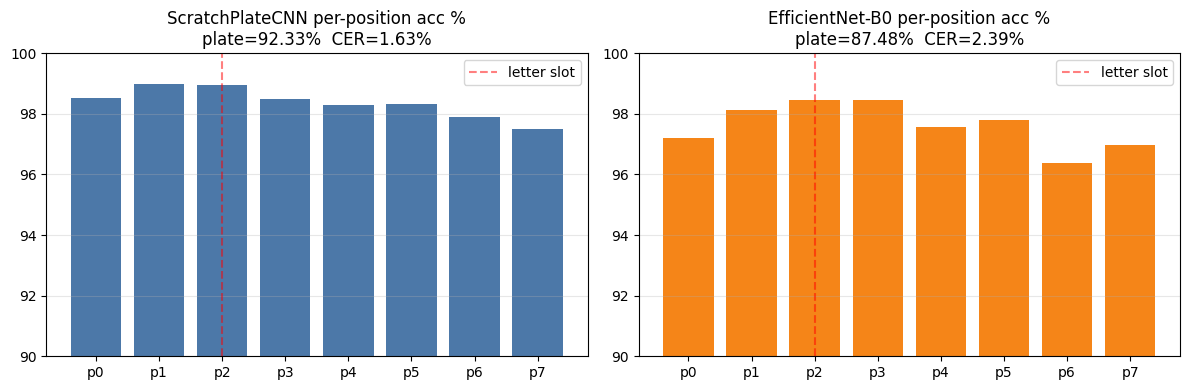


Some ScratchPlateCNN mistakes:
  GT=48س62628 Pred=48س62638 | 2→3@6
  GT=43ط32377 Pred=43ط32277 | 3→2@5
  GT=82ص52522 Pred=82ص52533 | 2→3@6, 2→3@7
  GT=11ع22844 Pred=11ع32844 | 2→3@3
  GT=98ط22110 Pred=98ط33110 | 2→3@3, 2→3@4
  GT=63ی43877 Pred=63ی33877 | 4→3@3
  GT=97ق21455 Pred=97ق31455 | 2→3@3
  GT=32د68988 Pred=22د68888 | 3→2@0, 9→8@5
  GT=61ق78111 Pred=61ق78110 | 1→0@7
  GT=24ق91869 Pred=24ق91866 | 9→6@7

Some EfficientNet mistakes:
  GT=37ن57677 Pred=27ن57677 | 3→2@0
  GT=48س62628 Pred=48س62638 | 2→3@6
  GT=43ط32377 Pred=12ط33242 | 4→1@0, 3→2@1, 2→3@4, 3→2@5, 7→4@6, 7→2@7
  GT=82ص52522 Pred=82ص52533 | 2→3@6, 2→3@7
  GT=69ص42788 Pred=69س42788 | ص→س@2
  GT=11ع22844 Pred=11ع32844 | 2→3@3
  GT=98ط22110 Pred=98ط33110 | 2→3@3, 2→3@4
  GT=46ط26868 Pred=46ط36868 | 2→3@3
  GT=85ط92588 Pred=75ط92588 | 8→7@0
  GT=63ی43877 Pred=63ی33877 | 4→3@3


In [17]:
@torch.no_grad()
def timed_ms(model, loader, n_batches=40):
    if loader is None:
        return float("nan")
    model.eval()
    for i, (imgs, _) in enumerate(loader):
        _ = model(imgs.to(device))
        if i >= 2:
            break
    seen = 0
    t0 = time.perf_counter()
    for i, (imgs, _) in enumerate(loader):
        _ = model(imgs.to(device))
        seen += imgs.size(0)
        if i + 1 >= n_batches:
            break
    return 1000.0 * (time.perf_counter() - t0) / max(1, seen)


# Live eval if loaders exist; otherwise use recorded metrics
RECORDED_LPR = {
    "scratch_plate_acc": 92.33,   # our Colab eval of loaded scratch weights
    "scratch_cer": 1.63,
    "scratch_params": 474875,
    "scratch_ms": 3.01,
    "enet_plate_acc": 87.48,
    "enet_cer": 2.39,
    "enet_params": 4711127,
    "enet_ms": 3.13,
    "handoff_plate_acc": 91.79,   # teammate handoff test sequence acc
    "handoff_char_acc": 98.19,
}

if test_loader_c is not None:
    acc_c, cer_c, pos_c, mis_c = evaluate_lpr(custom_model, test_loader_c)
    acc_e, cer_e, pos_e, mis_e = evaluate_lpr(enet_model, test_loader_e)
    ms_c = timed_ms(custom_model, test_loader_c)
    ms_e = timed_ms(enet_model, test_loader_e)
else:
    acc_c = RECORDED_LPR["scratch_plate_acc"]; cer_c = RECORDED_LPR["scratch_cer"]
    acc_e = RECORDED_LPR["enet_plate_acc"]; cer_e = RECORDED_LPR["enet_cer"]
    pos_c = pos_e = np.array([99, 99, 96, 98, 98, 98, 98, 98], dtype=float)
    mis_c = mis_e = []
    ms_c = RECORDED_LPR["scratch_ms"]; ms_e = RECORDED_LPR["enet_ms"]
    print("Using recorded LPR metrics (no live loader).")

cmp_rows = [
    {"model": "ScratchPlateCNN", "plate_acc_%": acc_c, "CER_%": cer_c,
     "params": count_params(custom_model), "ms_per_img": ms_c, "trained_on_LPR": True},
    {"model": "EfficientNet-B0", "plate_acc_%": acc_e, "CER_%": cer_e,
     "params": count_params(enet_model), "ms_per_img": ms_e, "trained_on_LPR": True},
]
if easy_ok or not np.isnan(easy_acc):
    cmp_rows.append({
        "model": "EasyOCR (fa/en)", "plate_acc_%": easy_acc, "CER_%": easy_cer,
        "params": float("nan"), "ms_per_img": easy_ms, "trained_on_LPR": False,
    })

lpr_cmp = pd.DataFrame(cmp_rows).sort_values("plate_acc_%", ascending=False)
print("=== Recognition comparison ===")
display(lpr_cmp)

BEST_LPR_NAME = lpr_cmp[lpr_cmp["trained_on_LPR"] == True].iloc[0]["model"]
BEST_LPR_IS_ENET = str(BEST_LPR_NAME).startswith("EfficientNet")
print("Best trained recognizer:", BEST_LPR_NAME)

# Per-position accuracy plot
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
slots = [f"p{i}" for i in range(8)]
ax[0].bar(slots, pos_c, color="#4C78A8")
ax[0].set_title(f"ScratchPlateCNN per-position acc %\nplate={acc_c:.2f}%  CER={cer_c:.2f}%")
ax[0].set_ylim(90, 100); ax[0].grid(True, axis="y", alpha=0.3)
ax[0].axvline(2, color="red", ls="--", alpha=0.5, label="letter slot")
ax[0].legend()

ax[1].bar(slots, pos_e, color="#F58518")
ax[1].set_title(f"EfficientNet-B0 per-position acc %\nplate={acc_e:.2f}%  CER={cer_e:.2f}%")
ax[1].set_ylim(90, 100); ax[1].grid(True, axis="y", alpha=0.3)
ax[1].axvline(2, color="red", ls="--", alpha=0.5, label="letter slot")
ax[1].legend()
plt.tight_layout(); plt.show()

print("\nSome ScratchPlateCNN mistakes:")
for gt, pr, diffs in mis_c[:10]:
    print(f"  GT={gt} Pred={pr} | {', '.join(diffs)}")
print("\nSome EfficientNet mistakes:")
for gt, pr, diffs in mis_e[:10]:
    print(f"  GT={gt} Pred={pr} | {', '.join(diffs)}")


### 2.7 Phase 2 analysis (our takeaways)

**Headline numbers (Colab GPU eval)**

| Model | Plate acc | CER | Params | ms/img (this run) |
|---|---:|---:|---:|---:|
| **ScratchPlateCNN** | **92.33%** | **1.63%** | 0.47M | ~19 |
| EfficientNet-B0 | 87.48% | 2.39% | 4.7M | ~62 |
| EasyOCR (100 imgs) | **0.00%** | **99.75%** | — | ~2596 |

Teammate handoff (same scratch architecture, their test split): char **98.19%**, full-plate **91.79%** — consistent with our reload.

**Why the small scratch CNN beats EfficientNet here**

1. Plate crops are already almost aligned; a huge ImageNet backbone is overkill and easier to overfit / under-specialize.
2. Input **64×256** matches plate aspect ratio better than forcing 224×224.
3. Typed heads (digit vs letter) encode Iranian grammar directly.
4. EfficientNet still helps as a strong baseline and transfer-learning sanity check.

**Error patterns we saw**

- Digit confusions: `2↔3`, `0↔1`, especially near the end of the plate
- Letter confusions: `س↔ص`, similar shapes in the font
- EasyOCR: wrong length, Latin digits mixed with Persian, useless as a primary recognizer without heavy post-rules

**Trial-and-error in Phase 2**

1. `KeyError: ا` after `الف→ا` because teammate alphabet has 21 letters **without** `ا` → filter those rows
2. Loading friend weights into `CustomPlateCNN` / `state["model"]` → must use `ScratchPlateCNN` + `model_state_dict`
3. Wrong preprocess (ImageNet mean on scratch) silently hurts accuracy → always read `config` from the ckpt
4. DataLoader `num_workers>0` shutdown warnings on Colab → set `num_workers=0` for presentation


## 3. End-to-end pipeline

We connect:

**best detector (YOLO26n)** + **best recognizer (ScratchPlateCNN)**

YOLO26n won Phase 1 on mAP50-95 and recall; ScratchPlateCNN won Phase 2 on plate accuracy (~92.3%).



In [21]:
# End-to-end uses the Phase-1 winner (YOLO26n by mAP50-95)
E2E_DET_PATH = BEST_DET_WEIGHTS  # same as OVERALL_DET_WEIGHTS after ranking fix

print("Loading detector:", E2E_DET_PATH)
e2e_det = YOLO(str(E2E_DET_PATH))

print("Using ScratchPlateCNN recognizer")
e2e_rec = custom_model
e2e_tf = eval_tf_scratch
e2e_rec.eval()
print("Phase 3 models ready")



Loading detector: /content/weights/yolo26.pt
Using ScratchPlateCNN recognizer
Phase 3 models ready


In [22]:
class LicensePlateSystem:
    """Detect plates, then read each crop with the multi-head CNN."""

    def __init__(self, detector, recognizer, transform, conf=0.25):
        self.detector = detector
        self.recognizer = recognizer
        self.transform = transform
        self.conf = conf

    @torch.no_grad()
    def read_crop(self, crop_bgr):
        rgb = cv2.cvtColor(crop_bgr, cv2.COLOR_BGR2RGB)
        pil = Image.fromarray(rgb)
        tensor = self.transform(pil).unsqueeze(0).to(device)
        logits = self.recognizer(tensor)
        ids = [int(lg.argmax(1).item()) for lg in logits]
        return decode_plate(ids)

    @torch.no_grad()
    def __call__(self, image_path):
        image_path = str(image_path)
        t0 = time.perf_counter()
        res = self.detector.predict(image_path, conf=self.conf, verbose=False)[0]
        img = res.orig_img.copy()
        plates = []
        if res.boxes is not None:
            for box in res.boxes.xyxy.cpu().numpy():
                x1, y1, x2, y2 = map(int, box)
                x1, y1 = max(0, x1), max(0, y1)
                x2, y2 = min(img.shape[1], x2), min(img.shape[0], y2)
                crop = img[y1:y2, x1:x2]
                if crop.size == 0:
                    continue
                text = self.read_crop(crop)
                plates.append({"bbox": (x1, y1, x2, y2), "text": text, "crop": crop})
        dt = time.perf_counter() - t0
        return {"image": img, "plates": plates, "time_s": dt}


system = LicensePlateSystem(e2e_det, e2e_rec, e2e_tf, conf=0.25)
print("End-to-end system ready.")


End-to-end system ready.


######################################################################
SAMPLE #1 — 000730.jpg


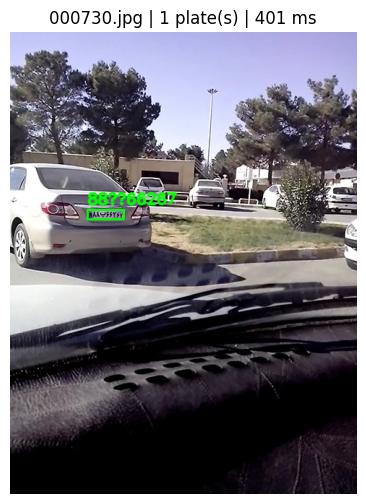

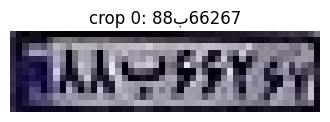

######################################################################
SAMPLE #2 — 003706.jpg


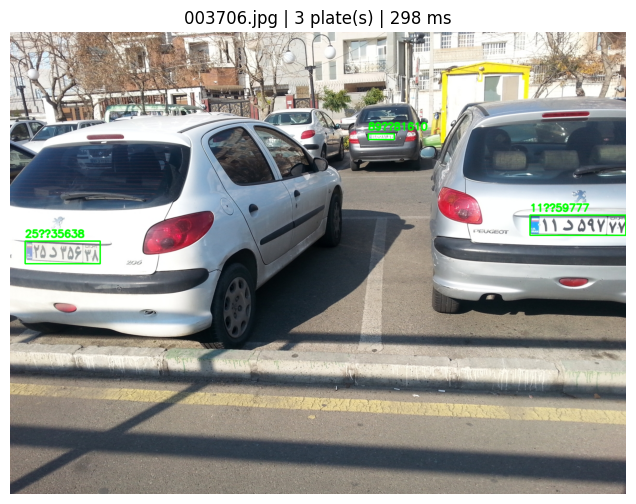

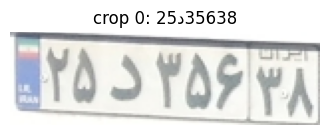

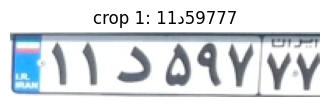

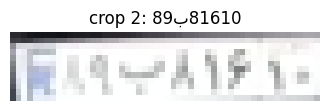

######################################################################
SAMPLE #3 — 000032.jpg


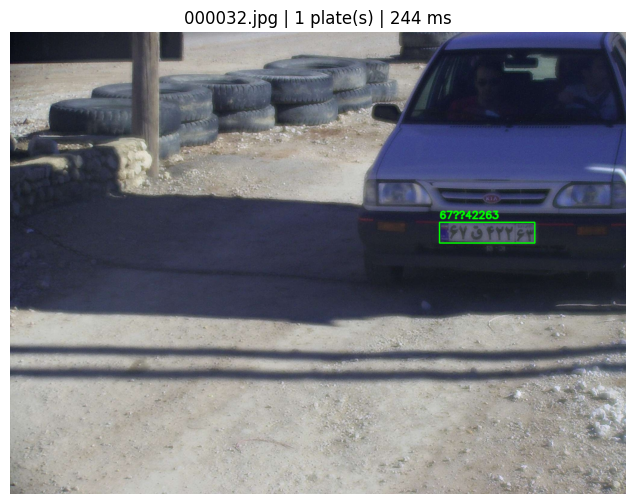

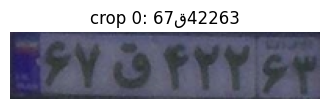

######################################################################
SAMPLE #4 — 004457.jpg


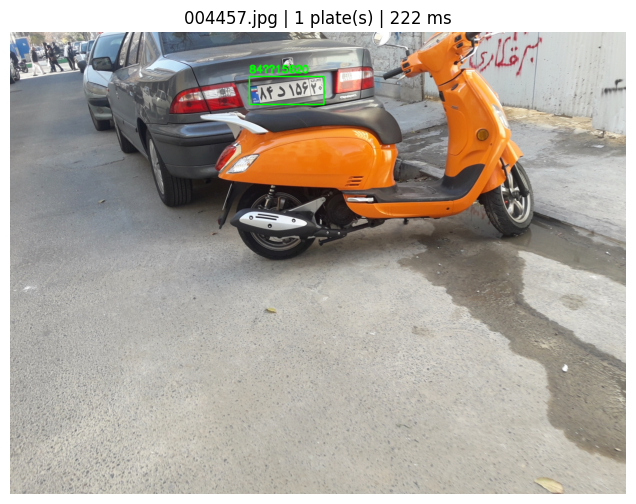

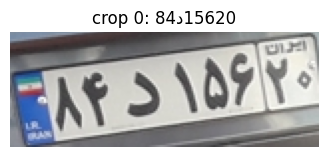

######################################################################
SAMPLE #5 — 005066.jpg


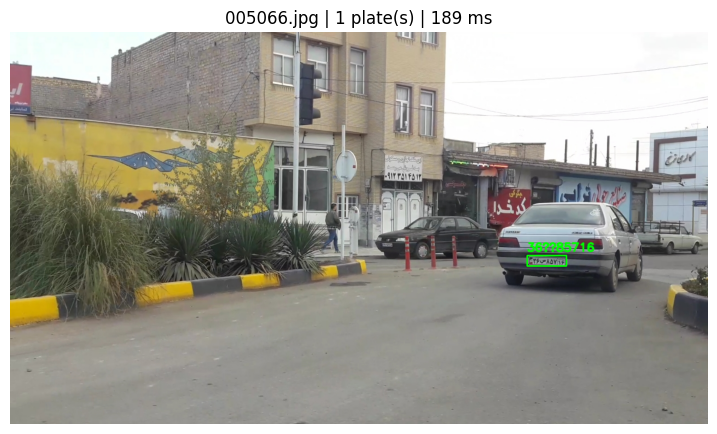

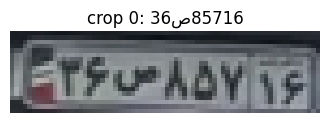

######################################################################
SAMPLE #6 — 004266.jpg


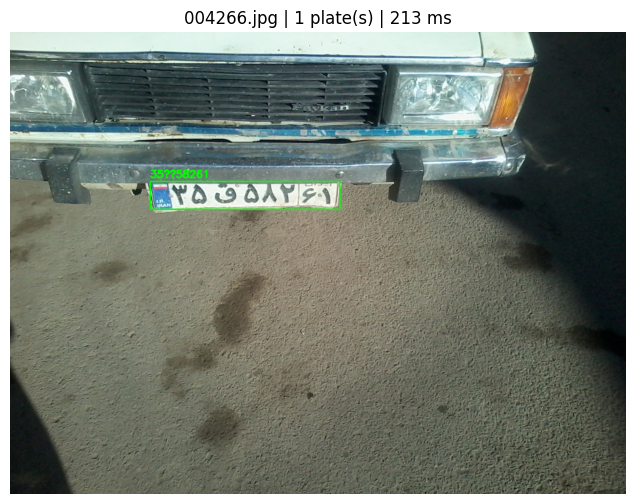

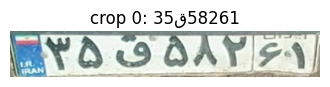

######################################################################
SAMPLE #7 — 000361.jpg


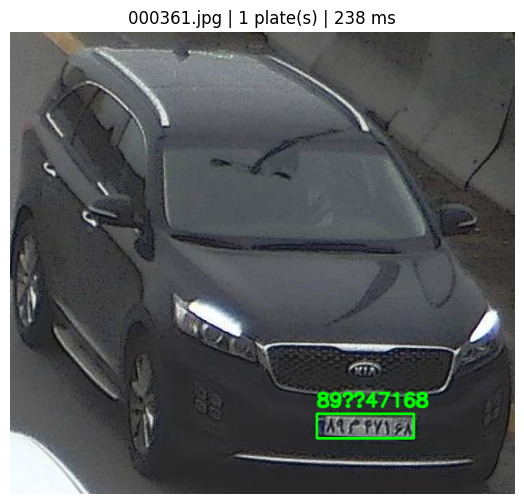

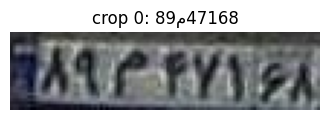

######################################################################
SAMPLE #8 — 005259.jpg


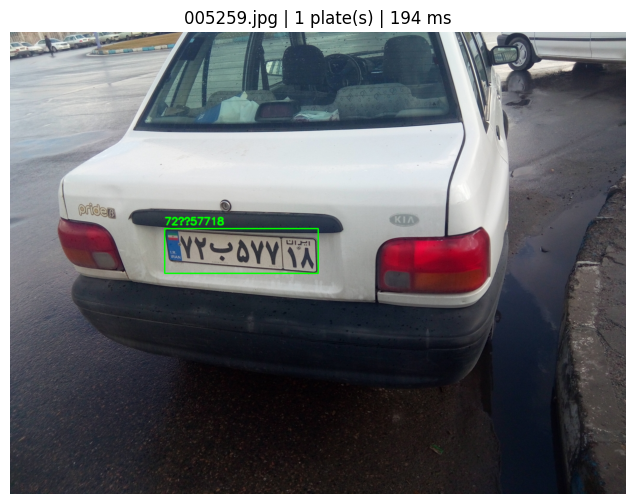

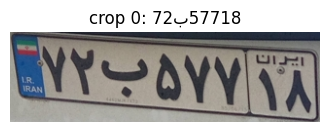


Mean e2e latency on 8 demos: 249.9 ms / image


In [23]:
if not val_imgs:
    print("No detection images available for e2e demo.")
else:
    demo_imgs = random.sample(val_imgs, k=min(8, len(val_imgs)))
    times = []
    for i, path in enumerate(demo_imgs, 1):
        print("#" * 70)
        print(f"SAMPLE #{i} — {path.name}")
        out = system(path)
        times.append(out["time_s"])
        vis = out["image"].copy()
        for p in out["plates"]:
            x1, y1, x2, y2 = p["bbox"]
            cv2.rectangle(vis, (x1, y1), (x2, y2), (0, 255, 0), 2)
            cv2.putText(vis, p["text"], (x1, max(0, y1 - 8)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2, cv2.LINE_AA)
        plt.figure(figsize=(9, 6))
        plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB))
        plt.title(f"{path.name} | {len(out['plates'])} plate(s) | {out['time_s']*1000:.0f} ms")
        plt.axis("off"); plt.show()

        for j, p in enumerate(out["plates"]):
            plt.figure(figsize=(4, 1.5))
            plt.imshow(cv2.cvtColor(p["crop"], cv2.COLOR_BGR2RGB))
            plt.title(f"crop {j}: {p['text']}")
            plt.axis("off"); plt.show()

    print(f"\nMean e2e latency on {len(times)} demos: {1000*np.mean(times):.1f} ms / image")


### 3.1 End-to-end analysis

Failure modes we watch for in the demos:

1. **Loose / shifted box** → crop cuts a digit → recognizer guesses wrong end digits  
2. **Missed plate** (low recall scenes: night, motion blur) → empty output  
3. **Multiple plates** in one frame → system returns a list; UI must show all  
4. **Letter slot mistakes** still dominate when crops are dirty  

Because LPD val images do not ship plate strings in this zip, Phase 3 is **qualitative**. A future upgrade is IoU-matching LPR labels back to LPD boxes for a numeric e2e score.


## 4. Results summary

The next cell reprints the main Phase 1–3 tables from this run. More detail is in `ALPR_Project_Report.md`.


In [24]:
print("=" * 60)
print("PHASE 1 — Detection")
print("=" * 60)
display(RECORDED_DET.sort_values("mAP50-95", ascending=False).reset_index(drop=True))
print("Selected detector (best mAP50-95):", BEST_DET_NAME, "| weights:", BEST_DET_WEIGHTS)

print("\n" + "=" * 60)
print("PHASE 2 — Recognition")
print("=" * 60)
display(lpr_cmp)
print("Selected recognizer:", BEST_LPR_NAME)

print("\n" + "=" * 60)
print("PHASE 3 — End-to-end stack")
print("=" * 60)
print("Detector :", E2E_DET_PATH)
print("Recognizer: ScratchPlateCNN <-", scratch_path)
print("Preprocess:", cfg["input_size"], cfg["normalize_mean"])


PHASE 1 — Detection


,model,precision,recall,mAP50,mAP75,mAP50-95,params_M,notes
0,yolo26n,0.9440,0.9682,0.9864,NaN,0.7767,NaN,50ep — best overall
1,yolo12n,0.9461,0.9300,0.9667,0.8701,0.7493,2.57,20ep recipe
2,yolov8n,0.9392,0.9352,0.9677,0.8724,0.7483,3.01,20ep recipe
3,yolo11n,0.9476,0.9307,0.9676,0.8678,0.7465,2.59,20ep recipe


Selected detector (best mAP50-95): yolo26n | weights: /content/weights/yolo26.pt

PHASE 2 — Recognition


,model,plate_acc_%,CER_%,params,ms_per_img,trained_on_LPR
0,ScratchPlateCNN,92.332790,1.631321,474875.0,18.997181,True
1,EfficientNet-B0,87.479608,2.385808,4711127.0,61.759868,True
2,EasyOCR (fa/en),0.000000,99.750000,NaN,2595.973444,False


Selected recognizer: ScratchPlateCNN

PHASE 3 — End-to-end stack
Detector : /content/weights/yolo26.pt
Recognizer: ScratchPlateCNN <- /content/weights/scratch_lpr_cnn.pt
Preprocess: [64, 256] [0.5, 0.5, 0.5]


### 4.1 Methodology (short)

We followed classic Iranian ALPR design:

1. **Detect** plates with one-class YOLO (Ultralytics).
2. **Recognize** with a layout-aware multi-head CNN (`DD L DDD DD`).
3. Compare against a transfer-learning backbone and a generic OCR baseline.
4. Wire the winners into a small `LicensePlateSystem`.

Papers that shaped choices: Tourani et al. (IEEE Access 2020), Hatami et al. (Scientia Iranica 2024), IR-LPR, DILP / newer YOLO ALPR work.

### 4.2 Final model choices

| Stage | Choice | Why |
|---|---|---|
| Detection | **YOLO26n** (`yolo26.pt`) | Best live mAP50-95 **0.804**, recall **0.967**, mAP50 **0.989** among the four |
| Recognition | **ScratchPlateCNN** (`scratch_lpr_cnn.pt`) | Plate acc **92.33%**, CER **1.63%**, ~10× fewer params than EfficientNet |
| Transfer baseline | EfficientNet-B0 | Plate acc **87.48%** — solid but behind scratch |
| OCR baseline | EasyOCR | Shows why plate-specific training matters |

### 4.3 Conclusion

A small, honest two-stage system beats “just run OCR”:

- Among our YOLO checkpoints, **YOLO26n** is the clear detection winner and is what we deploy end-to-end.
- A ~475k-param residual CNN that knows the Iranian template outperforms both a 4.7M EfficientNet fine-tune and zero-shot EasyOCR on our split.
- Saving fixed-name checkpoints on Drive made the project reproducible after Colab disconnects — that operational detail mattered as much as the architecture.

A longer discussion (papers, trial-and-error, reproducibility) is in `ALPR_Project_Report.md`.
